# survpm: что есть в библиотеке и как ею пользоваться

Демонстрационный ноутбук к выступлению. Версия библиотеки — **0.3.0**. Каждый шаг: короткое пояснение и
рабочая ячейка. Весь ноутбук выполняется примерно за минуту.

## Идея в трёх пунктах

1. **Журнал событий с цензурой.** У каждого объекта (пациента, заявки, станка) есть трасса состояний
   с временами. Часть трасс не доходит до исхода: наблюдение оборвалось. Про последнее ожидание такой трассы
   известно только, что оно **длилось дольше** `c` дней, и неизвестно, куда объект пошёл бы дальше.
   Если такие ожидания выбросить, времена получаются заниженными.

2. **Сеть состояний с временами (конкурирующие риски).** Из состояния `s` по каждому исходящему ребру
   `s → d` независимо «тикают» экспоненциальные часы с интенсивностью `rate_sd` (1/день); побеждает первый.
   Отсюда `p_sd = rate_sd / Σ rate` — вероятность выхода по ребру и `1 / Σ rate` — среднее ожидание.
   Цензурированное ожидание даёт **экспозицию всем выходам** состояния, поэтому оценка
   `rate_sd = (число переходов s→d) / (суммарное время в s, включая незавершённые ожидания)`.
   Сеть переводится в **сеть Петри** с отдельным местом `CENS` для оборвавшихся трасс.

3. **Выживание.** По модели считаются `S(t) = P(ещё не дошёл до исхода через t дней)`, прогноз для
   идущего объекта с учётом уже прошедшего времени, вероятности повторов состояний, и всё это
   сравнивается с данными (NLL с цензурой, метрики process mining, Каплан–Майер).

## План

| # | Шаг | Главные объекты |
|---|---|---|
| 1 | Синтетика с известной истиной: зачем нужна цензура | `Network`, `ExponentialTransitionModel`, `ModelGenerator` |
| 2 | Реальные данные Sepsis: `EventLog`, правила трасс, интервалы | `datasets`, `EventLog.prepare`, `intervals` |
| 3 | Структура процесса и рисунки | `discover`, `GraphvizVisualizer` |
| 4 | Модель и сеть Петри | `ProcessModel`, `edges_table`, `plot("petri")` |
| 5 | Признаки объектов | `ExponentialTransitionModel(log_features=...)`, `fit(features=...)` |
| 6 | Кривые выживания и остаточное время | `MarkovForecaster`, `SimulationForecaster`, `legacy().survival / state_curves / residual_survival` |
| 7 | Вероятность повтора события | `repeat_table` |
| 8 | Генерация журнала | `log.starts`, `ModelGenerator`, `compare_networks` |
| 9 | Оценка качества | `evaluate`, `compare`, `CrossValidator` |
| 10 | Сохранение модели | `save`, `load` |

### 0. Подключение

Библиотека лежит в `dima/survpm` (установка: `pip install -e "survpm[metrics]"`, для рисунков ещё
`brew install graphviz`). Ниже путь добавляется вручную, чтобы ноутбук работал и без установки.

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"   # без прогресс-баров PM4Py
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.max_columns", 20, "display.width", 140)

import survpm
print("survpm", survpm.__version__)

survpm 0.3.0


## 1. Синтетика с известной истиной: зачем нужна цензура

Зададим истинный процесс руками: сеть `A → B → C → D` с возвратами и известными интенсивностями.
`Network.from_edges` — структура, `ExponentialTransitionModel(rates=...)` — времена, `ProcessModel` —
их композиция. Такую модель можно сразу использовать для генерации.

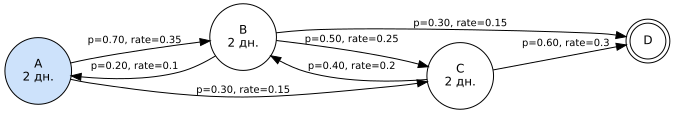

In [2]:
TRUE_RATES = {("A", "B"): .35, ("A", "C"): .15,
              ("B", "A"): .10, ("B", "C"): .25, ("B", "D"): .15,
              ("C", "B"): .20, ("C", "D"): .30}
true_net = survpm.Network.from_edges(list(TRUE_RATES), starts=["A"], terminals=["D"])
truth = survpm.ProcessModel(true_net, survpm.ExponentialTransitionModel(rates=TRUE_RATES))
truth.plot()          # сеть с rate, p и средним ожиданием (graphviz)

**Генерация с цензурой.** `EventLog.start(600, "A", t0)` — журнал из 600 новых объектов в состоянии `A`;
`ModelGenerator(truth).generate(start, horizon=6)` продолжает каждый объект 6 дней. Кто не дошёл до `D`
за горизонт — цензурирован (`event = 0`). Результат — обычный `EventLog`, как из реальных данных.

In [3]:
RULES_AD = {"starts": ["A"], "terminals": ["D"]}
start = survpm.EventLog.start(600, "A", "2025-01-01")
syn = survpm.ModelGenerator(truth, seed=1).generate(start, horizon=6.).prepare(RULES_AD)
display(syn.observation.groupby(["event", "reason"]).size().rename("объектов"))
syn.intervals().head(6)

event  reason 
0      horizon    287
1                 313
Name: объектов, dtype: int64

,case_id,src,dst,duration,observed,reason,enter
0,case-0,A,B,0.453,True,,2025-01-01 00:00:00+00:00
1,case-0,B,D,0.935,True,,2025-01-01 10:51:37.080816233+00:00
2,case-1,A,B,2.570,True,,2025-01-01 00:00:00+00:00
3,case-1,B,D,2.485,True,,2025-01-03 13:40:35.322262086+00:00
4,case-10,A,C,0.024,True,,2025-01-01 00:00:00+00:00
5,case-10,C,D,1.117,True,,2025-01-01 00:34:19.377999270+00:00


`intervals()` — главная таблица для оценки: каждое ожидание в состоянии `src`, его длительность и
куда ушёл объект. У цензурированных ожиданий `observed = False` и `dst` пустой.

Обучим две модели на одних данных: с учётом цензуры (по умолчанию) и **наивную**, которая выбрасывает
незавершённые ожидания. Сравним с истиной.

In [4]:
aware = survpm.ProcessModel(true_net).fit(syn)
naive = survpm.ProcessModel(true_net).fit(syn, use_censoring=False)
rates = pd.DataFrame({"истина": TRUE_RATES,
                      "с цензурой": aware.edges_table().set_index(["src", "dst"]).rate,
                      "наивная": naive.edges_table().set_index(["src", "dst"]).rate})
rates.round(3)

истина  с цензурой  наивная
A B    0.35       0.360    0.423
  C    0.15       0.161    0.189
B A    0.10       0.098    0.152
  C    0.25       0.249    0.387
  D    0.15       0.151    0.234
C B    0.20       0.204    0.312
  D    0.30       0.281    0.430

Наивная модель **завышает интенсивности** (= занижает время ожидания): она не видит объекты,
которые долго сидели в состоянии и не успели выйти. Учёт цензуры возвращает оценки к истине.

## 2. Реальные данные: Sepsis и `EventLog`

`EventLog` хранит четыре таблицы:

* `events` — `case_id, activity, timestamp` (трассы состояний);
* `cases` — статические признаки объекта (возраст, диагноз, флаги SIRS…);
* `measurements` — замеры во времени в длинном формате `case_id, timestamp, feature, value` (CRP, лейкоциты, лактат);
* `observation` — конец наблюдения: `end`, `event` (1 = дошёл до исхода), `reason`.

Признаки разбираются автоматически. Свой журнал читается так же:
`survpm.read_log(path, "case_id", "activity", "timestamp")` или `EventLog.from_frame(df, mapping)`.

In [5]:
PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"
raw_log = survpm.datasets.load_sepsis_log(PATH)
print("статические:", raw_log.static[:8], "...")
print("замеры:", raw_log.dynamic)
display(raw_log.events.head(4))
display(raw_log.measurements.head(4))

статические: ['InfectionSuspected', 'DiagnosticBlood', 'DisfuncOrg', 'SIRSCritTachypnea', 'Hypotensie', 'SIRSCritHeartRate', 'Infusion', 'DiagnosticArtAstrup'] ...
замеры: ['CRP', 'LacticAcid', 'Leucocytes']


,case_id,activity,timestamp
0,A,Registration,2014-10-22 09:15:41+00:00
1,A,Examination,2014-10-22 09:27:00+00:00
2,A,Examination,2014-10-22 09:27:00+00:00
3,A,Examination,2014-10-22 09:27:00+00:00


,case_id,timestamp,feature,value
0,A,2014-10-22 09:27:00+00:00,Leucocytes,9.6
1,A,2014-10-22 09:27:00+00:00,CRP,21.0
2,A,2014-10-22 09:27:00+00:00,LacticAcid,2.2
3,A,2014-10-24 07:00:00+00:00,Leucocytes,8.7


**Правила трасс** задаются один раз в `prepare`: откуда считать время (`starts`) и что считается
исходом (`terminals`). Трасса обрезается после первого исхода; одинаковые состояния в один момент
склеиваются (`repeats="simultaneous"`, по умолчанию), а поздний повтор остаётся петлёй `s → s` —
это важно для вероятности повтора (шаг 7). Правила сохраняются в `log.rules`, дальше их повторять не нужно.

`split(seed=1)` делит по **целым объектам**, доля цензурированных в train и test одинакова.

In [6]:
RULES = {"starts": ["Registration"], "terminals": ["Discharge"]}
log = raw_log.prepare(RULES)
train, test = log.split(seed=1)
print("объектов train/test:", len(train.case_ids), len(test.case_ids))
display(log.observation.groupby(["event", "reason"]).size().rename("объектов"))
train.intervals().head()

объектов train/test: 840 210


event  reason
0      lost      268
1                782
Name: объектов, dtype: int64

,case_id,src,dst,duration,observed,reason,enter
0,AAA,Registration,Treatment,2.280e-03,True,,2014-11-19 02:16:21+00:00
1,AAA,Treatment,Examination,1.623e-02,True,,2014-11-19 02:19:38+00:00
2,AAA,Examination,Treatment,8.376e-02,True,,2014-11-19 02:43:00+00:00
3,AAA,Treatment,Admission,6.944e-04,True,,2014-11-19 04:43:37+00:00
4,AAA,Admission,Discharge,3.240e+00,True,,2014-11-19 04:44:29+00:00


## 3. Структура процесса и рисунки

`survpm.discover(train)` строит сеть как DFG по журналу без внешних зависимостей (есть и
`survpm.Pm4pyBackend("dfg")`). `GraphvizVisualizer` рисует DFG с числом переходов и наблюдаемые
доли выходов и цензуры по состояниям.

состояний: 5  рёбер: 15


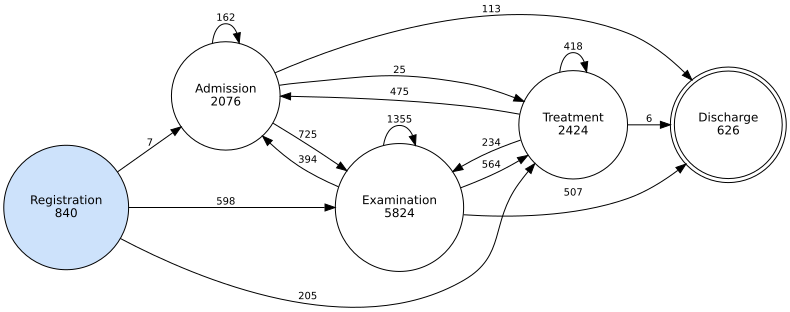

In [7]:
viz = survpm.GraphvizVisualizer()
network = survpm.discover(train)
print("состояний:", len(network.states), " рёбер:", len(network.edges))
viz.plot_dfg(train)

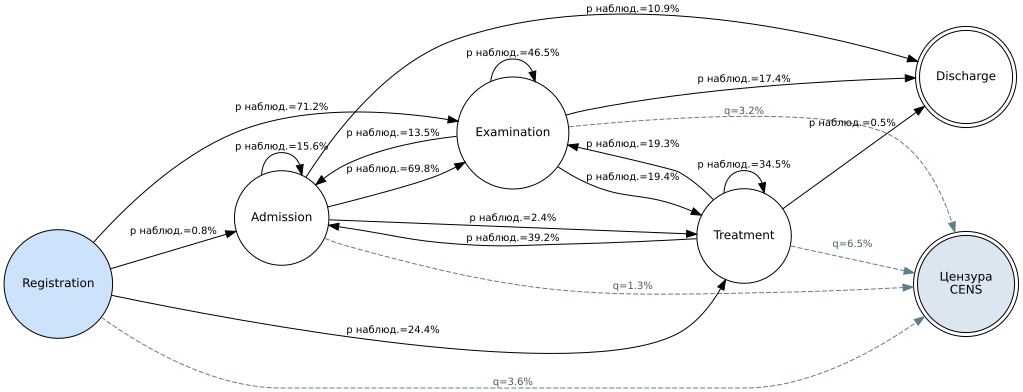

In [8]:
viz.plot_censoring(train)   # доли выходов из каждого состояния, включая обрыв наблюдения (CENS)

## 4. Модель и сеть Петри

`ProcessModel(network).fit(train)` оценивает интенсивности с учётом цензуры (без `network` сеть
строится по журналу сама). `fit` возвращает **новый** объект. `edges_table()` — главная таблица модели:
`rate`, `p` и среднее ожидание в состоянии `mean_days`.

In [9]:
model = survpm.ProcessModel(network).fit(train)
model.edges_table().sort_values(["src", "p"], ascending=[True, False]).head(10)

,src,dst,n_completed,n_visits,rate,p,mean_days
12,Admission,Examination,725,1038,0.529,0.707,1.337
13,Admission,Admission,162,1038,0.118,0.158,1.337
11,Admission,Discharge,113,1038,0.082,0.110,1.337
14,Admission,Treatment,25,1038,0.018,0.024,1.337
8,Examination,Examination,1355,2912,0.397,0.480,1.210
7,Examination,Treatment,564,2912,0.165,0.200,1.210
9,Examination,Discharge,507,2912,0.149,0.180,1.210
10,Examination,Admission,394,2912,0.116,0.140,1.210
1,Registration,Examination,598,840,38.754,0.738,0.019
0,Registration,Treatment,205,840,13.285,0.253,0.019


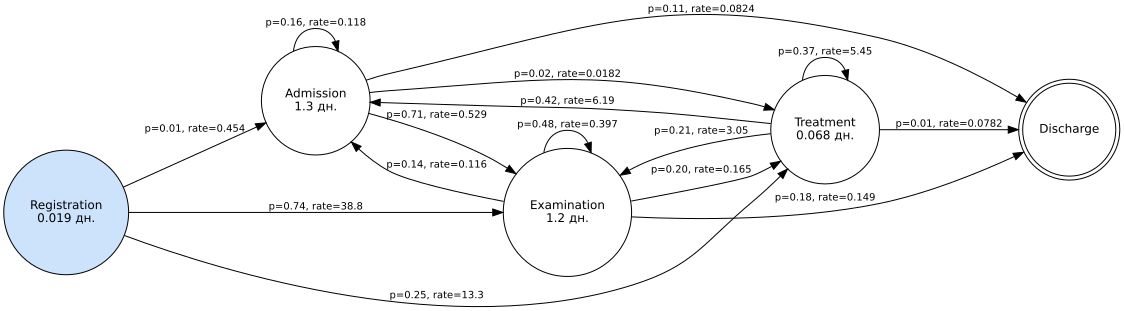

In [10]:
model.plot()            # сеть состояний: p, rate и среднее ожидание

Та же модель как **сеть Петри PM4Py**: места — состояния, переходы — рёбра, тихие переходы ведут
в место `CENS` с долей оборвавшихся ожиданий. `model.to_pm4py()` возвращает `(net, im, fm)` для
любых инструментов PM4Py.

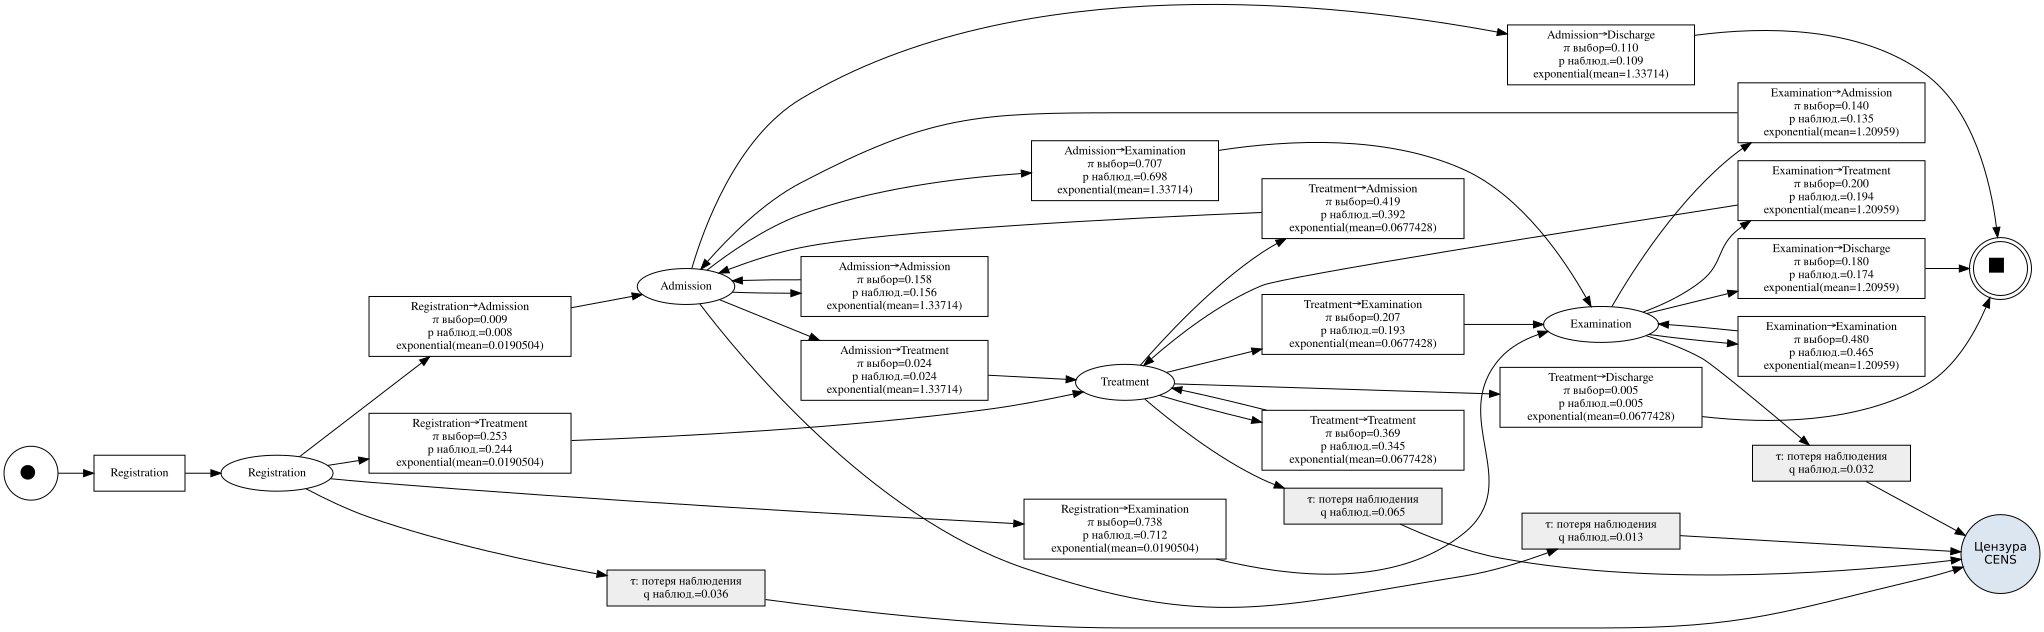

In [11]:
model.plot("petri")

## 5. Признаки объектов

Интенсивность может зависеть от признаков объекта на **момент входа** в состояние:
`log rate_sd(x) = log rate_sd + β_sd · x` (регрессия с L2-штрафом). Признаки берутся «как известно
на этот момент» (последний замер не позже входа, без заглядывания в будущее). Кроме признаков журнала
есть признаки истории: `history_visits` (сколько раз уже был в состоянии), `history_elapsed_days`.

`log_features` — `log1p` для скошенных анализов; значения обрезаются до диапазона train (`clip=True`).
Сравниваем по NLL на test (чем меньше, тем лучше; цензурированные ожидания входят через `S(c)`).

In [12]:
LABS = ["CRP", "Leucocytes", "LacticAcid"]
FEATURES = ["Age", *LABS, "history_visits", "history_elapsed_days"]
featured = survpm.ProcessModel(network, survpm.ExponentialTransitionModel(log_features=LABS)).fit(
    train, features=FEATURES)
naive_sepsis = survpm.ProcessModel(network).fit(train, use_censoring=False)
models = {"base": model, "naive": naive_sepsis, "features": featured}
survpm.compare(models, test, "nll").pivot(index="model", columns="metric", values="value")

metric,nll_per_interval,nll_per_trace
model,,
base,0.955,7.005
features,0.375,2.750
naive,0.955,7.005


На Sepsis наивная и censor-aware модели совпадают: у большинства цензурированных трасс время от
последней записи до конца наблюдения близко к нулю (в журнале нет явного конца наблюдения). Признаки же
дают заметный выигрыш по NLL.

## 6. Кривые выживания и остаточное время

**Прогноз для конкретного объекта.** Прогноз получает журнал на момент «сейчас»: `test.cut(t)` оставляет
события и замеры до `t` и ставит `end = t`. `survival` — `S(t)` до исхода, `expected_time` — среднее время
до исхода в пределах горизонта, `terminal_probs`, `hazard`; горизонты — дни от `end`.
`MarkovForecaster` считает формулой (признаки фиксированы на «сейчас»), `SimulationForecaster` — долей
Монте-Карло путей и пересчитывает признаки истории на каждом шаге.

In [13]:
case_id = test.case_ids[0]
trace = test.events.loc[test.events.case_id == case_id]
t = trace.timestamp.iloc[1]                           # стоим после второго события
now = test.cut(t).select([case_id])
print("история до t:", now.events.activity.tolist())
times = [1., 3., 7., 14., 30.]
pd.DataFrame({"base, формула": survpm.MarkovForecaster(model).survival(now, times).set_index("horizon").survival,
              **{name: survpm.SimulationForecaster(m, n_paths=500, seed=1).survival(now, times).set_index("horizon").survival
                 for name, m in {"base": model, "features": featured}.items()}})

история до t: ['Registration', 'Examination']


,"base, формула",base,features
horizon,,,
1.0,0.868,0.838,0.876
3.0,0.666,0.654,0.640
7.0,0.399,0.406,0.316
14.0,0.164,0.172,0.088
30.0,0.021,0.024,0.004


In [14]:
survpm.SimulationForecaster(featured, n_paths=500, seed=1).expected_time(now, horizon=30.)

,case_id,restricted_mean_time,probability_unfinished
0,A,6.061,0.004


**Кривые без симуляции.** `model.legacy()` даёт эквивалентный `CensoredStateNet` с теми же
интенсивностями. Он считает `S(t)` точно на сетке (уравнение марковского восстановления, свёртка со
сдвигом), без случайности:

* `survival(t, method="grid")` — от старта процесса;
* `state_curves(horizon)` — `S_s(t)` от входа в каждое состояние `s`;
* `residual_survival(state, elapsed, t)` — остаток для идущего объекта, который уже `elapsed` дней в `state`.

Сравним `S(t)` модели с Капланом–Майером по test.

sup |S - S_KM| = 0.157
остаток из Admission через 7 дней, уже 0 / 10 дней в Admission: [0.435, 0.435]


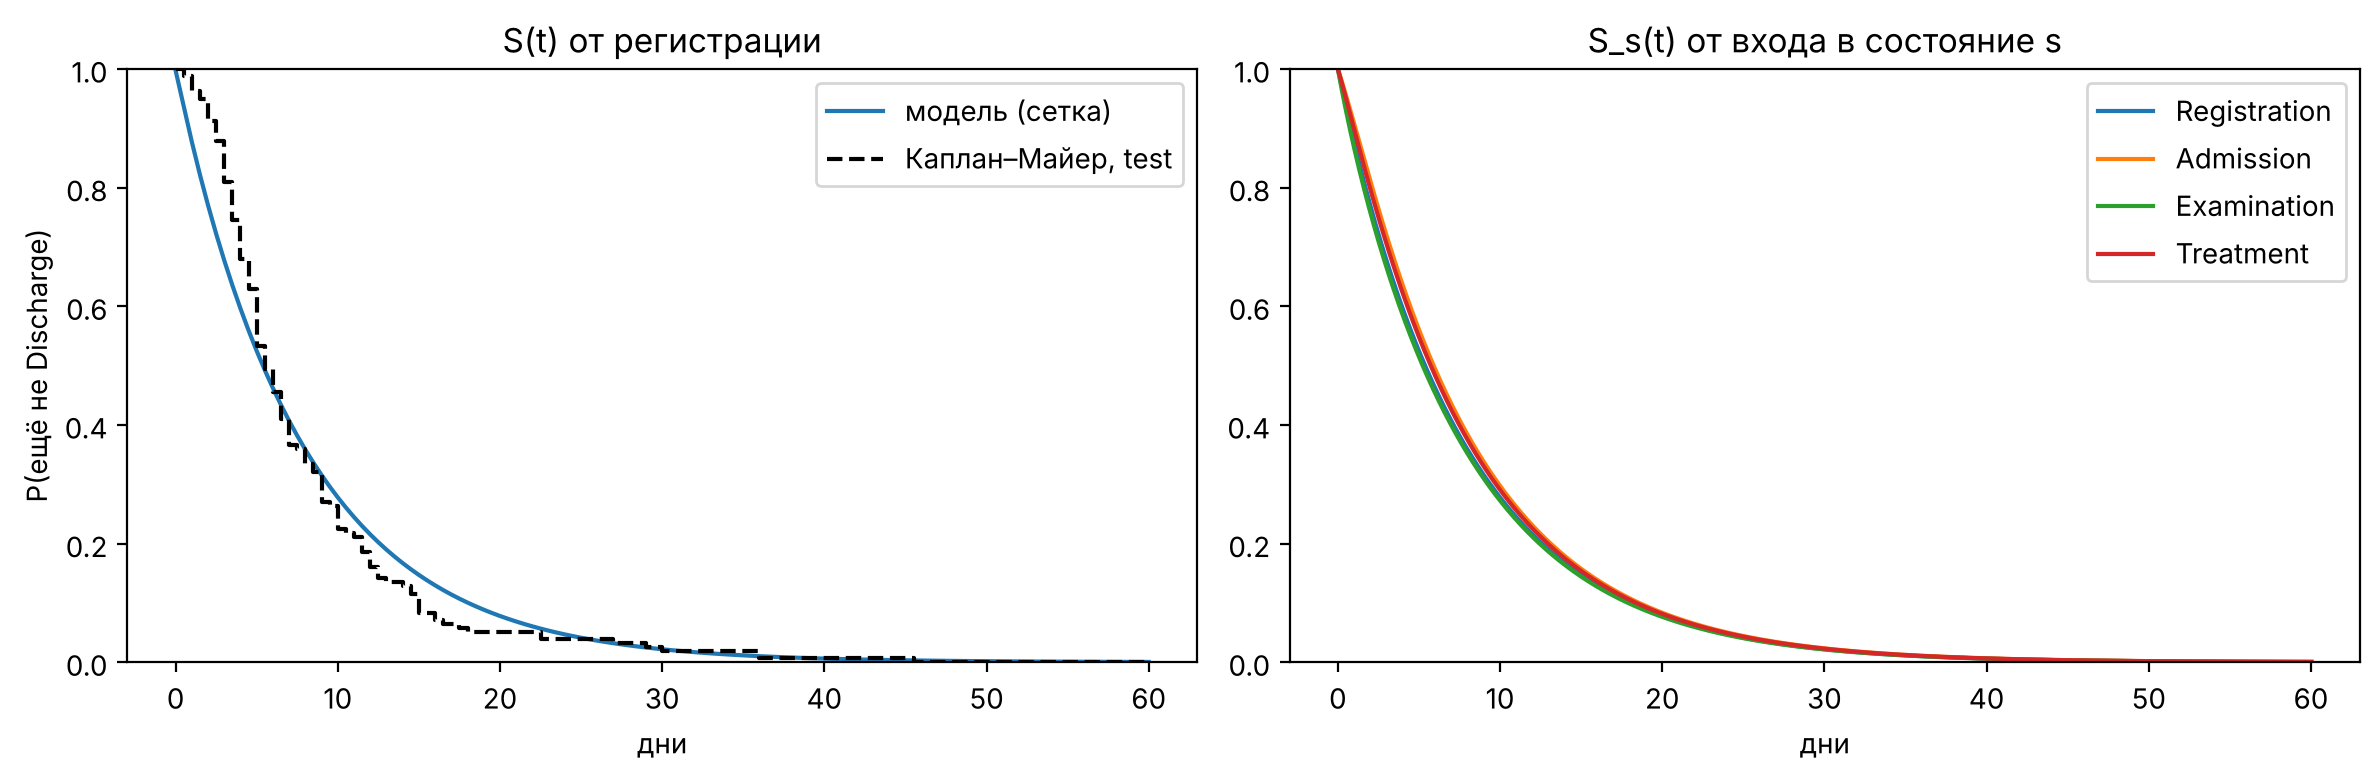

In [15]:
net = model.legacy()
grid = np.linspace(0, 60, 121)
S_model = net.survival(grid, method="grid", step=.05)

obs = test.observation.set_index("case_id")
entry = test.events.groupby("case_id").timestamp.min()
dur = ((obs.end - entry.reindex(obs.index)).dt.total_seconds() / 86400).to_numpy()
done = (obs.event == 1).to_numpy()
# Каплан–Майер «вручную», без lifelines
S_km = np.array([np.prod([1 - np.sum((dur == u) & done) / np.sum(dur >= u)
                          for u in np.unique(dur[done & (dur <= t)])]) for t in grid])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(grid, S_model, label="модель (сетка)")
ax[0].step(grid, S_km, where="post", ls="--", color="k", label="Каплан–Майер, test")
ax[0].set(title="S(t) от регистрации", xlabel="дни", ylabel="P(ещё не Discharge)", ylim=(0, 1)); ax[0].legend()
curves = net.state_curves(60, step=.05)
for state in ["Registration", "Admission", "Examination", "Treatment"]:
    c = curves.loc[curves.state == state]
    ax[1].plot(c.time_days, c.survival, label=state)
ax[1].set(title="S_s(t) от входа в состояние s", xlabel="дни", ylim=(0, 1)); ax[1].legend()
plt.tight_layout()
print("sup |S - S_KM| =", round(float(np.max(np.abs(S_model - S_km))), 3))
print("остаток из Admission через 7 дней, уже 0 / 10 дней в Admission:",
      [round(float(net.residual_survival("Admission", a, [7.], step=.05)[0]), 3) for a in (0, 10)])

In [16]:
curves.loc[np.isclose(curves.time_days % 7, 0, atol=.026) & (curves.time_days > 0)].pivot_table(
    index="state", columns=curves.time_days.round().astype(int), values="survival").round(2)

time_days,0,7,14,21,28,35,42,49,56
state,,,,,,,,,
Admission,1.0,0.43,0.18,0.07,0.03,0.01,0.01,0.0,0.0
Discharge,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0
Examination,1.0,0.40,0.16,0.07,0.03,0.01,0.00,0.0,0.0
Registration,1.0,0.41,0.17,0.07,0.03,0.01,0.00,0.0,0.0
Treatment,1.0,0.42,0.17,0.07,0.03,0.01,0.00,0.0,0.0


Таблица выше — `S_s(t)` из каждого состояния на 7/14/…/56 день: «если пациент сейчас вошёл в `s`,
какова вероятность, что он ещё не выписан через t дней». На Sepsis кривые из разных состояний почти
совпадают: из любого состояния путь до выписки занимает около недели.

Что видно на рисунках и где предел модели: экспоненциальные времена не дают «задержки» в начале, поэтому
модельная `S(t)` в первые дни ниже Каплана–Майера (sup-расхождение ≈ 0.16). По той же причине у модели
нет памяти: `residual_survival` не зависит от `elapsed` (в выводе выше одинаковые числа для 0 и 10 дней).
Разница появится при неэкспоненциальных временах (прежний режим `choice_then_time`, см. `docs/legacy.md`).

## 7. Вероятность повтора события

Отдельный интерес — **вероятность, что событие повторится** (повторная госпитализация, повторный
анализ, повторная поломка). Поэтому по умолчанию трассы **не упрощаются**: `Examination` остаётся
состоянием, а поздний повтор — петлёй `s → s`.

`repeat_table()` по вероятностям выходов считает для каждого состояния:
* `p_immediate` — следующее состояние то же самое;
* `p_return` — состояние ещё встретится до исхода (сразу или через другие);
* `expected_visits = 1 / (1 − p_return)` — среднее число заходов.

Сравним с долями в самом журнале (по трассам, дошедшим до исхода).

In [17]:
def log_repeats(prepared):
    done = prepared.observation.loc[prepared.observation.event == 1, "case_id"]
    rows = []
    for _, trace in prepared.events.loc[prepared.events.case_id.isin(done)].groupby("case_id", sort=False):
        acts = trace.activity.tolist()
        rows += [dict(state=s, p_immediate_log=acts[i + 1] == s, p_return_log=s in acts[i + 1:])
                 for i, s in enumerate(acts[:-1])]
    return pd.DataFrame(rows).groupby("state").mean()

net.repeat_table().set_index("state").join(log_repeats(train)).round(3)

,p_immediate,p_return,expected_visits,p_immediate_log,p_return_log
state,,,,,
Admission,0.158,0.604,2.523,0.160,0.384
Examination,0.480,0.782,4.589,0.498,0.770
Registration,0.000,0.000,1.000,0.000,0.000
Treatment,0.369,0.665,2.981,0.342,0.453


Для `Examination` модель хорошо воспроизводит повторы. Для `Admission`/`Treatment` поздние возвраты
модель переоценивает: экспонента «не помнит», сколько раз объект уже возвращался. Это и есть мотивация
признака `history_visits` из шага 5: с ним интенсивность возврата зависит от числа прошлых визитов.

## 8. Генерация журнала

`train.starts(prefix="syn-")` — те же объекты с теми же моментами старта (первое событие каждого);
`ModelGenerator(model).generate(...)` выдаёт синтетический `EventLog` (с цензурой на горизонте).
Проверка модели «туда и обратно»: по синтетике снова находим сеть и интенсивности и сравниваем с исходными.
Своя динамика признаков (сценарии) — своя реализация `StreamData.at`, переданная как `ModelGenerator(model, data=...)`.

In [18]:
starts = train.starts(prefix="syn-")
synthetic = survpm.ModelGenerator(model, seed=7).generate(starts, horizon=60.)
display(synthetic.events.head(5))

recovered = survpm.discover(synthetic.prepare(RULES))
print({k: round(v, 3) for k, v in survpm.compare_networks(network, recovered).items() if k in ("precision", "recall", "f1")})
refit = survpm.ProcessModel(network).fit(synthetic)
model.edges_table()[["src", "dst", "rate"]].merge(refit.edges_table()[["src", "dst", "rate"]],
                                                   on=["src", "dst"], suffixes=("_model", "_synthetic")).head(8)

,case_id,activity,timestamp
0,syn-AAA,Registration,2014-11-19 02:16:21+00:00
1,syn-AAA,Examination,2014-11-19 02:34:38.381102710+00:00
2,syn-AAA,Examination,2014-11-22 15:33:28.475265842+00:00
3,syn-AAA,Discharge,2014-11-22 23:49:21.714914614+00:00
4,syn-AB,Registration,2014-02-16 08:55:43+00:00


{'precision': 1.0, 'recall': 1.0, 'f1': 1.0}


,src,dst,rate_model,rate_synthetic
0,Registration,Treatment,13.285,14.503
1,Registration,Examination,38.754,39.915
2,Registration,Admission,0.454,0.457
3,Treatment,Examination,3.049,3.124
4,Treatment,Admission,6.189,6.169
5,Treatment,Treatment,5.446,5.503
6,Treatment,Discharge,0.078,0.059
7,Examination,Treatment,0.165,0.158


## 9. Оценка качества

Одна точка входа `survpm.evaluate(model, log, metrics)` и один формат результата — **длинная таблица**
`level, model, metric, value`. Метрики сгруппированы по уровням:

| Уровень | Что меряет |
|---|---|
| `nll` | правдоподобие с цензурой на test |
| `level1` | process mining: fitness, precision (token replay), generalization, simplicity |
| `level2` | стохастические: entropic relevance, uEMSC, EMD путей |
| `level3` | временные: temporal profile, KS по рёбрам, `km_sup`, log-rank, IBS |
| `level4` | доля трасс с неизвестными переходами и NLL без них |

Полный список — `survpm.available_metrics()`; своя метрика добавляется `register_metric(name, func)`.

In [19]:
survpm.available_metrics().groupby("level", sort=False).metric.apply(", ".join).to_frame()

,metric
level,
nll,nll
level1,"fitness_token, precision_token, generalization..."
level2,"entropic_relevance, uemsc, emd"
level3,"temporal_deviation_share, cfld, ngram_3, cycle..."
level4,"unseen_share, nll_per_interval, nll_per_trace"


In [20]:
res = survpm.compare({"base": model, "naive": naive_sepsis}, test, ["nll", "level1", "level4"])
res.pivot_table(index=["level", "metric"], columns="model", values="value", sort=False)

model                     base  naive
level  metric                        
nll    nll_per_interval  0.955  0.955
       nll_per_trace     7.005  7.005
level1 fitness_token     1.000  1.000
       precision_token   0.583  0.583
       generalization    0.758  0.758
       simplicity        0.524  0.524
level4 nll_per_interval  0.955  0.955
       nll_per_trace     7.005  7.005
       unseen_share      0.000  0.000

**Кросс-валидация** по целым трассам: фолды равны по доле цензурированных трасс, в каждом фолде
сравниваются naive и censor-aware модели (и Inductive Miner для метрик уровня 1). Начало и исход
берутся из `log.rules`. Для скорости здесь 3 фолда и только `level4`; для полного прогона —
`CrossValidator(k=5).add_metrics("all")`.

In [21]:
from survpm.metrics.crossval import CrossValidator, summarize
cv = CrossValidator(k=3).add_metrics("level4").run(log, progress=None)
summarize(cv["level4"])

unseen_share      nll_per_interval        nll_per_trace       
                     mean  std             mean    std          mean    std
model                                                                      
naive                 0.0  0.0            1.067  0.036         7.663  0.178
censor_aware          0.0  0.0            1.067  0.036         7.663  0.178

## 10. Сохранение модели

Модель сохраняется целиком (сеть, интенсивности, кодировщик признаков, обучающий журнал) и загружается
обратно (pickle — только из доверенных файлов).

In [22]:
import tempfile, os
path = os.path.join(tempfile.mkdtemp(), "sepsis_featured.pkl")
featured.save(path)
loaded = survpm.ProcessModel.load(path)
print("NLL до/после загрузки:",
      survpm.evaluate(featured, test, "nll").value.round(4).tolist(),
      survpm.evaluate(loaded, test, "nll").value.round(4).tolist())

NLL до/после загрузки: [0.3748, 2.7504] [0.3748, 2.7504]


## Итог: что есть и чего пока нет

**Есть**
* `EventLog` — единый журнал (события, статические признаки, замеры, конец наблюдения) и правила трасс;
* структура: DFG без внешних зависимостей, бэкенд PM4Py, сравнение сетей;
* модель конкурирующих экспоненциальных рисков с учётом цензуры, с признаками и историей;
* сеть Петри с местом `CENS`, рисунки graphviz/matplotlib;
* генерация журналов (`ModelGenerator`), прогноз для идущего объекта (`MarkovForecaster`, `GridForecaster`,
  `SimulationForecaster`), точные кривые выживания на сетке, вероятности повторов;
* метрики уровней 1–4 в одном формате, кросс-валидация, сохранение моделей;
* ядро на numpy/pandas/scipy, PM4Py (AGPL) подключается только по требованию.

**Точки расширения** — свой бэкенд структуры (`PetriBackend`), своя модель переходов (`TransitionModel`),
свои признаки к моменту (`StreamData`), своё правило выбора перехода (`Selector`), своя метрика (`register_metric`), свой рисунок (`Visualizer`).

**Ограничения и следующие шаги**
* в режиме v2 только экспоненциальные времена (без памяти) → переоценка поздних повторов;
* метрики уровней 1–3 пока только для модели без признаков (для модели с признаками — `nll`);
* на Sepsis нет явного конца наблюдения, поэтому эффект цензуры там слабый; на синтетике он виден чётко;
* скрытые состояния — в планах; формульный прогноз фиксирует признаки на «сейчас», изменение признаков
  по пути учитывает только `SimulationForecaster`.

Подробнее: `dima/survpm/README.md`, `dima/sepsis_minimal.ipynb`, `dima/petri_net_time_estimation*.ipynb`.